In [19]:
from pathlib import Path
import sys

project_root = next(
    path for path in (Path.cwd(), *Path.cwd().parents)
    if (path / "lib" / "useful.py").is_file()
)
if str(project_root) not in sys.path:
    sys.path.insert(0, str(project_root))

from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import classification_report, confusion_matrix
from sklearn.preprocessing import StandardScaler
from lib.useful import load_split_mnist, save_model, load_model
import matplotlib.pyplot as plt
import seaborn as sns


In [ ]:
X_train, X_test, y_train, y_test = load_split_mnist(train_csv_path='../data/datasets/MNIST_train.csv', test_csv_path='../data/datasets/MNIST_test.csv')

scaler = StandardScaler()
mnist_classifier = KNeighborsClassifier(5)

In [21]:
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

mnist_classifier.fit(X_train_scaled, y_train)

,n_neighbors,5
,weights,'uniform'
,algorithm,'auto'
,leaf_size,30
,p,2
,metric,'minkowski'
,metric_params,None
,n_jobs,None


In [22]:
y_pred = mnist_classifier.predict(X_test_scaled)
results = classification_report(y_test, y_pred)
print(results)


              precision    recall  f1-score   support

           0       0.95      0.98      0.97       980
           1       0.95      0.99      0.97      1135
           2       0.96      0.93      0.94      1032
           3       0.92      0.95      0.93      1010
           4       0.95      0.94      0.94       982
           5       0.93      0.93      0.93       892
           6       0.96      0.97      0.97       958
           7       0.94      0.93      0.93      1027
           8       0.96      0.90      0.93       974
           9       0.92      0.92      0.92      1009

    accuracy                           0.94      9999
   macro avg       0.94      0.94      0.94      9999
weighted avg       0.94      0.94      0.94      9999



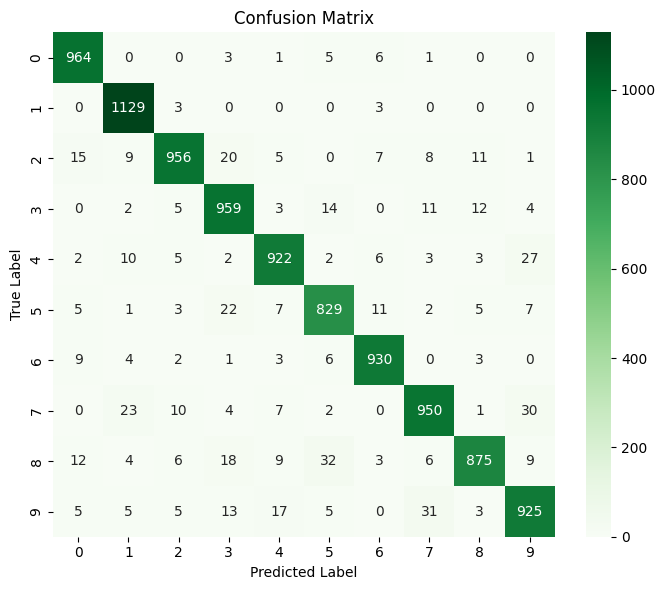

In [28]:
classes = list(range(10))
cm = confusion_matrix(y_test, y_pred, labels=classes)

plt.figure(figsize=(7, 6))
sns.heatmap(
    cm,
    annot=True,
    fmt='d',
    cmap='Greens',
    xticklabels=classes,
    yticklabels=classes,
)

plt.xlabel('Predicted Label')
plt.ylabel('True Label')
plt.title('Confusion Matrix')
plt.tight_layout()
plt.show()
